# Milestone 3 - Notebook candidat : moteur de consolidation des livraisons

**But du document :** donner une compréhension **complète** du moteur de consolidation : sur quoi il repose (postulats et hypothèses, imputations), quelles règles il respecte, comment il décide, ce qu'il produit.

**Objectif métier retenu :** **baisser le coût de transport** (saving) sans jamais livrer en retard ni dépasser la capacité d'un camion. Le moteur n'impose ni minimum de jours, ni minimum de camions, ni profil le plus bas : il prend, pour chaque couple, le plan admissible **le moins cher** ; à coût égal, il garde le profil le plus bas. Chaque camion part un jour du profil de son couple, y compris la première semaine ; les livraisons peuvent commencer jusqu'à 7 jours avant le premier besoin (dès le 02/11).

| Section | Contenu |
| :--- | :--- |
| **1** | Postulats et hypothèses (données, imputations, calendrier, transport, chargement, référence) |
| **2** | Règles de gestion RG01 à RG12 et la façon dont le moteur respecte chacune |
| **3** | Fonctionnement précis de l'algorithme et règles de décision, avec un exemple pas à pas |
| **4** | Situation actuelle mesurée au Milestone 2 : indicateurs de référence et cartes de chaleur |
| **5** | Résultats : profils, coûts, saving |
| **6** | Lissage : sans lissage, lissage gratuit (plan retenu), petit lissage payant |
| **7** | Indicateurs complémentaires |
| **8** | Les trois sorties |
| **9** | Synthèse et limites |

**Entrées :** `data/consolidated_dataset.csv` (dataset consolidé, section 1.1), `docs/rate_sheet.csv` (grille tarifaire), `data/baseline_deliveries.csv` et `data/baseline_kpis.csv` (situation actuelle du Milestone 2). Les données brutes de `docs/` ne servent qu'à tracer les hypothèses de nettoyage (section 1).

**Moteur :** `src/delivery_schedule_optimization/planner.py`.

## Paramètres communs

Tous les paramètres métier sont dans `PlannerConfig` (EF12) : on les change ici, sans toucher au code. Trois scénarios de lissage sont calculés pour la comparaison de la section 6.

In [1]:
from __future__ import annotations

import logging
from dataclasses import asdict, replace
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

from delivery_schedule_optimization import planner as pl

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)-7s %(message)s", datefmt="%H:%M:%S", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
logger = logging.getLogger("candidate")

DATA_DIR, DOCS_DIR, OUTPUT_DIR = Path("../data"), Path("../docs"), Path("../data")
SMALL_SMOOTHING_BUDGET = 0.005  # "petit lissage" scenario: 0.5 % of extra cost accepted to spread the days
cfg = pl.PlannerConfig()  # retained plan: cost first, free smoothing (budget 0)

PLANT_COLORS = {"PLT_001": "#2a78d6", "PLT_002": "#eb6834", "PLT_003": "#1baf7a", "PLT_004": "#eda100"}
SCENARIO_COLORS = {"A - actuel": "#9c9a92", "B0 - sans lissage": "#eb6834",
                   "B1 - lissage gratuit (retenu)": "#2a78d6", "B2 - petit lissage": "#1baf7a"}
MUTED, PRIMARY = "#52514e", "#2a78d6"
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e4e3df",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
pd.set_option("display.max_colwidth", 160)
eur = lambda x: f"{x:,.0f}".replace(",", " ")
pct = lambda x: f"{x:.1f}".replace(".", ",")  # French decimal comma
EXPLANATIONS = {
    "truck_kg": "RG04 : poids maximal d'un camion (kg)",
    "truck_m3": "RG04 : volume maximal d'un camion (m³)",
    "margin": "RG11 : marge du transporteur (2,3923 = 239,23 %)",
    "diesel_surcharge": "RG11 : coefficient de surcharge diesel",
    "max_advance_days": "RG03 : avance maximale d'une livraison, en jours calendaires",
    "allowed_frequencies": "RG05 : profils autorisés (livraisons max par semaine)",
    "holiday_country": "RG10 : calendrier des jours fériés (DE = Allemagne)",
    "smoothing": "RG09 : True = lissage actif, False = chaque couple garde son plan le moins cher",
    "smoothing_budget": "RG09 : surcoût accepté pour lisser, en part du coût (0 = lissage gratuit, 0,005 = 0,5 %)",
    "smoothing_time_limit": "Temps maximal du solveur de lissage par problème (s), garde-fou technique",
    "objective": "Critère principal : cost = coût le plus bas, trucks = moins de camions",
    "lowest_profile_first": "True = profil le plus bas avant le coût (ancienne lecture de RG07)",
    "lowest_profile_at_equal_cost": "True = à coût égal, le profil le plus bas ; le lissage n'augmente jamais le profil d'un couple",
    "overflow_first": "True = moins de départs à plusieurs camions avant le coût (préférence client)",
    "improvement_passes": "Moteur glouton de comparaison (reference_plan) seulement, pas utilisé ici",
    "plan_start": "H11 : premier jour de départ possible (advance = premier besoin − 7 jours, soit le 02/11 ; None = date du premier besoin, 09/11)",
    "strict_coverage": "RG06 : False = un besoin part avec n'importe quel départ prévu dans sa fenêtre ; True = avec le dernier départ avant sa date",
    "reassign_passes": "Nombre maximal de passes de l'amélioration de l'affectation (RG06 assouplie)",
    "workers": "Nombre de processus pour calculer les plans candidats (None = tous les cœurs, 1 = sans parallélisme) ; le résultat ne change pas",
}
params = pd.Series(asdict(cfg)).to_frame("valeur")
params["explication"] = params.index.map(EXPLANATIONS)
assert params["explication"].notna().all(), "a parameter has no explanation"

## 1. Postulats et hypothèses

Tout ce que le moteur **suppose** sans pouvoir le vérifier dans les données. Chaque hypothèse a une raison et une conséquence sur le résultat ; celles qui sont réglables le sont par un paramètre.

### 1.1 Données et nettoyage (Milestone 1, `consolidated_dataset.csv`)

| ID | Hypothèse | Raison | Conséquence |
| :--- | :--- | :--- | :--- |
| **H01** | Une ligne du planning = un besoin : un material, livré à un quai d'une usine, un jour donné | Dictionnaire des données du sujet | Unité de base du moteur ; on ne la découpe jamais |
| **H02** | Quantité = 0 → pas de besoin, la ligne est retirée | Sujet (« 0 = pas de besoin ») | 959 lignes retirées |
| **H03** | Les lignes du 01/01/2027 sont un **cumul** des besoins après l'horizon journalier, pas un vrai besoin du jour | Date unique, volumes anormaux, 01/01 férié | 379 lignes retirées ; horizon réel 09/11 → 18/12 (6 semaines) |
| **H04** | Une ligne plus lourde qu'un camion (> 24,5 t) est retirée | Elle ne peut tenir dans aucun camion (RG04) | 1 ligne retirée |
| **H05** | **Poids ou volume manquant ou nul → complété par un camion plein** (24 500 kg, 110,4 m³ ; section 1.5) | Prudent : on surestime la charge plutôt que de la sous-estimer | 134 poids et 116 volumes concernés ; chacune de ces lignes occupe **un camion entier**, à la référence comme au plan |
| **H06** | **Distance manquante → complétée par la distance maximale** des fournisseurs du planning (149 km) | On ne sous-estime pas le coût | SUP_00130 (4 lignes) |
| **H07** | `transmission_date` et `version_date` sont ignorées | Consigne du professeur | Le moteur ne tient pas compte de la date d'envoi du programme au fournisseur |
| **H08** | Les poids et volumes d'une ligne sont ceux de la **commande**, pas unitaires | Dictionnaire des données | Le chargement d'une livraison = somme des lignes |

### 1.2 Calendrier

| ID | Hypothèse | Raison | Conséquence |
| :--- | :--- | :--- | :--- |
| **H09** | Livraisons du lundi au vendredi uniquement | Réponse client : pas de réception les jours non ouvrés | Un besoin du week-end partirait un jour ouvré avant (aucun dans les données) |
| **H10** | Jours fériés = calendrier national allemand (`holidays`, DE) | Usines en Allemagne | Aucun jour férié entre le 02/11 et le 18/12 |
| **H11** | **Les livraisons peuvent commencer avant le premier besoin**, au plus tôt le **02/11** (09/11 − 7 jours) | Le planning est connu à l'avance ; seule la fenêtre de 7 jours (RG03) limite l'anticipation | Les besoins de la 1re semaine sont traités comme les autres : ils partent un jour du profil compris dans leur fenêtre, éventuellement la semaine du 02/11. Aucun départ hors profil (`plan_start = "advance"`) |
| **H12** | Anticipation de 7 jours **calendaires** (week-end compris) | Sujet : « on ne peut pas avancer une livraison de plus d'une semaine » ; réponse client | Un départ couvre au plus 8 dates de besoin consécutives (du jour J à J+7) |
| **H13** | Aucun stock ni capacité de réception n'est limité côté usine | Aucune donnée | L'avance n'est pas pénalisée (elle est seulement mesurée) ; le lissage est un objectif, pas une capacité de quai |

### 1.3 Transport et coût

| ID | Hypothèse | Raison | Conséquence |
| :--- | :--- | :--- | :--- |
| **H14** | Un camion transporte au plus 24 500 kg **et** 110,4 m³ ; il est plein dès qu'une limite est atteinte | Sujet | Contrôlé camion par camion (RG04) |
| **H15** | **Un camion = un envoi**, facturé sur **son propre poids** | Sujet : la grille donne un coût par envoi | Une livraison de 2 camions paie 2 envois |
| **H16** | Prix d'un envoi = coût grille(distance, poids) × (1 + 239,23 %) × 1,1943 | Sujet, `rate_sheet.pdf` | Coefficient ≈ × 4,05 sur la grille |
| **H17** | Les tranches de la grille se lisent « jusqu'à » (121 km → tranche 125 km ; 1 001 kg → tranche 1 500 kg) | Lecture de la grille | Bornes inclusives |
| **H18** | Au-delà de 4 000 kg, le tarif de la colonne « > 4 000 » s'applique **par envoi** (forfait) | Sujet (« à confirmer ») | Un camion de 5 t et un camion de 24 t coûtent le même prix |
| **H19** | La distance est celle du fournisseur au point de consolidation, la même pour toutes ses usines | `distances.csv` n'a qu'une distance par fournisseur | Le prix ne dépend pas de l'usine |

### 1.4 Chargement et référence

| ID | Hypothèse | Raison | Conséquence |
| :--- | :--- | :--- | :--- |
| **H20** | Dans le plan, une ligne est chargée **entière** dans un camion | Traçabilité : chaque besoin est dans un camion identifié (sortie 2) | La référence est chargée de la même façon (H21) : le saving compare deux chargements identiques |
| **H21** | **Référence (situation actuelle) = les livraisons du Milestone 2** (une par couple et par jour de besoin), **rechargées camion par camion comme le plan** : lignes entières, chaque camion facturé sur son poids (même référence que la branche `main`) | Les deux côtés du saving sont mesurés de la même façon | 176 724,61 € et 1 741 camions au lieu des 176 979,32 € et 1 744 camions de l'estimateur du Milestone 2, qui découpe la charge en continu et compte un camion de trop sur 3 livraisons (arrondi en virgule flottante) |
| **H22** | Le **profil** d'un couple = le **plus grand nombre de livraisons faites en une semaine** (3, 2, 1, 1, 2, 1 → profil 3), sur un **ensemble fixe de jours** | Définition validée en équipe | Une semaine peut utiliser une partie des jours, jamais un autre jour |
| **H23** | L'objectif est le **coût** : aucun minimum de jours ou de camions n'est imposé | Objectif final du projet | Un départ peut prendre un 2e camion si c'est moins cher qu'un jour de plus |

### 1.5 Méthode d'imputation

Les données manquantes sont complétées de façon **prudente** (Milestone 1, `consolidated_dataset.csv`) ; tout le reste (lignes, quantités, poids / volumes / distances connus) est inchangé.

| Donnée manquante | Valeur imputée |
| :--- | :--- |
| **Poids** (quantité > 0, poids vide ou nul) | 24 500 kg : la capacité d'un camion |
| **Volume** | 110,4 m³ : la capacité d'un camion |
| **Distance** (fournisseur absent de `distances.csv`) | **distance maximale** des fournisseurs du planning |
| **Effet** | chaque ligne imputée occupe un camion entier : coût et camions surestimés, à la référence comme au plan |

Les deux cellules suivantes vérifient ces hypothèses à partir des fichiers bruts : la première refait les comptages de H02 à H06, la seconde **recalcule l'imputation** et vérifie que le dataset consolidé en est exactement le résultat.

In [2]:
raw = pd.read_csv(DOCS_DIR / "released_schedule.csv", parse_dates=["date"])
distances_raw = pd.read_csv(DOCS_DIR / "distances.csv")
with_need = raw[raw["schedule_quantity"] > 0]
daily = with_need[with_need["date"] < "2027-01-01"]
kept = daily[~(daily["weight"] > 24_500)]
trace = pd.DataFrame({"lignes": {
    "planning brut (released_schedule.csv)": len(raw),
    "H02 - quantité > 0": len(with_need),
    "H03 - sans le cumul du 01/01": len(daily),
    "H04 - sans les lignes plus lourdes qu'un camion": len(kept),
}})
display(trace)

lines = pl.load_lines(DATA_DIR / "consolidated_dataset.csv", cfg)
assert len(lines) == len(kept), "the consolidated dataset does not follow from the raw file"
missing_weight = kept["weight"].isna() | (kept["weight"] <= 0)
missing_volume = kept["volume"].isna() | (kept["volume"] <= 0)
planning_suppliers = set(kept["supplier_id"])
no_distance = sorted(planning_suppliers - set(distances_raw.dropna(subset=["distance"])["supplier_id"]))
pd.DataFrame({"valeur": {
    "H05 - lignes sans poids (→ 24 500 kg)": int(missing_weight.sum()),
    "H05 - lignes sans volume (→ 110,4 m³)": int(missing_volume.sum()),
    "H05 - lignes complétées par un camion plein (dataset consolidé)": int(lines["imputed_full_truck"].sum()),
    "H06 - fournisseurs du planning sans distance": ", ".join(no_distance),
    "H06 - distance retenue pour eux (km)": float(lines.loc[lines["supplier_id"].isin(no_distance), "distance"].max()),
    "H06 - distance maximale des autres fournisseurs (km)": float(lines.loc[~lines["supplier_id"].isin(no_distance), "distance"].max()),
    "H09 - lignes un samedi ou un dimanche": int((lines["date"].dt.day_of_week >= 5).sum()),
    "horizon": f"{lines['date'].min():%d/%m/%Y} → {lines['date'].max():%d/%m/%Y}",
    "couples fournisseur × usine": lines.groupby(pl.COUPLE).ngroups,
}})

,lignes
planning brut (released_schedule.csv),5728
H02 - quantité > 0,4769
H03 - sans le cumul du 01/01,4390
H04 - sans les lignes plus lourdes qu'un camion,4389


,valeur
H05 - lignes sans poids (→ 24 500 kg),134
"H05 - lignes sans volume (→ 110,4 m³)",116
H05 - lignes complétées par un camion plein (dataset consolidé),134
H06 - fournisseurs du planning sans distance,SUP_00130
H06 - distance retenue pour eux (km),149.00
H06 - distance maximale des autres fournisseurs (km),149.00
H09 - lignes un samedi ou un dimanche,0
horizon,09/11/2026 → 18/12/2026
couples fournisseur × usine,180


In [3]:
print("Imputation : camion plein (24 500 kg, 110,4 m³) ; distance maximale des fournisseurs du planning")

key_columns = ["date", "supplier_id", "material", "plant", "unloading_point"]
merged = kept.merge(lines, on=key_columns, suffixes=("_raw", ""), validate="1:1")

rows = {}
for column, capacity in (("weight", cfg.truck_kg), ("volume", cfg.truck_m3)):
    # Imputed value recomputed from the raw file: a full truck
    missing = merged[f"{column}_raw"].isna() | (merged[f"{column}_raw"] <= 0)
    assert np.allclose(merged.loc[missing, column], capacity), f"{column}: imputation differs from the stated method"
    assert np.allclose(merged.loc[~missing, column], merged.loc[~missing, f"{column}_raw"]), f"{column}: known values changed"
    rows[{"weight": "poids", "volume": "volume"}[column]] = {"valeurs manquantes": int(missing.sum()), "camion plein": int(missing.sum()),
                                                            "valeur imputée": float(capacity)}

known = distances_raw.dropna(subset=["distance"]).drop_duplicates("supplier_id").set_index("supplier_id")["distance"]
known = known[known.index.isin(planning_suppliers)]
distance_rule = known.max()
supplier_distance = lines.drop_duplicates("supplier_id").set_index("supplier_id")["distance"]
assert np.allclose(supplier_distance[no_distance], distance_rule), "distance: imputation differs from the stated method"
assert np.allclose(supplier_distance[known.index], known), "distance: known values changed"
rows["distance"] = {"valeurs manquantes": len(no_distance), "valeur imputée": float(distance_rule)}
print("Le dataset consolidé suit exactement la méthode annoncée ; les valeurs connues sont inchangées.")
pd.DataFrame(rows).T.fillna(0)

Imputation : camion plein (24 500 kg, 110,4 m³) ; distance maximale des fournisseurs du planning
Le dataset consolidé suit exactement la méthode annoncée ; les valeurs connues sont inchangées.


,valeurs manquantes,camion plein,valeur imputée
poids,134.00,134.00,24 500.00
volume,116.00,116.00,110.40
distance,1.00,0.00,149.00


In [4]:
tariff = pl.Tariff(pl.load_rate_grid(DOCS_DIR / "rate_sheet.csv"), cfg)
holidays = pl.public_holidays(lines, cfg)
in_horizon = sorted(d for d in holidays if lines["date"].min().date() <= d <= lines["date"].max().date())
print("H10 - jours fériés allemands dans l'horizon :", in_horizon or "aucun")
print(f"H16 - coefficient de prix : (1 + {cfg.margin}) × {cfg.diesel_surcharge} = {cfg.price_factor:.4f}")
example = pd.DataFrame({"distance (km)": [121, 121, 121, 121], "poids du camion (kg)": [1_000, 1_001, 4_000, 24_500]})
example["prix (EUR)"] = tariff(example["distance (km)"], example["poids du camion (kg)"])
print("H17 / H18 - lecture de la grille (« jusqu'à », forfait au-delà de 4 000 kg) :")
example

H10 - jours fériés allemands dans l'horizon : aucun
H16 - coefficient de prix : (1 + 2.3923) × 1.1943 = 4.0514
H17 / H18 - lecture de la grille (« jusqu'à », forfait au-delà de 4 000 kg) :


,distance (km),poids du camion (kg),prix (EUR)
0,121,1000,146.86
1,121,1001,181.87
2,121,4000,321.97
3,121,24500,331.41


## 2. Règles de gestion

Les règles viennent du sujet (`consolidation_algorithme_pdf.pdf`) et des spécifications du Milestone 1. Pour chacune : sa formalisation et la façon dont le moteur la respecte **par construction**.

| ID | Règle | Formalisation | Comment le moteur la respecte |
| :--- | :--- | :--- | :--- |
| **RG01** | Consolidation par couple fournisseur × usine | Un camion = un fournisseur et une usine ; il peut desservir plusieurs quais de l'usine | Chaque couple est planifié séparément |
| **RG02** | Jamais de retard | jour de livraison ≤ date du besoin | Un besoin part avec un départ **à sa date ou avant** |
| **RG03** | Anticipation ≤ 7 jours calendaires | date du besoin − jour de livraison ≤ 7 | Un départ qui servirait un besoin à plus de 7 jours est interdit |
| **RG04** | Capacité d'un camion | Σ poids ≤ 24 500 kg et Σ volume ≤ 110,4 m³ | Chargement des lignes entières, camion par camion |
| **RG05** | Profil de livraison | Profil = 1 à 5 livraisons par semaine (4 autorisé), sur un **ensemble fixe** de jours ouvrés | Seuls les jours de l'ensemble sont des jours de départ, première semaine comprise (seule exception : jour férié avancé, RG10) |
| **RG06** | Couverture | **Assouplie (décision d'équipe) :** chaque besoin part avec **n'importe quel départ prévu** de son couple dans sa fenêtre [date − 7 j ; date]. La lecture stricte du sujet (« un jour de livraison couvre les besoins jusqu'au jour de livraison suivant ») reste disponible : `strict_coverage=True` | Les jours de départ sont choisis, puis chaque besoin est placé dans le départ qui coûte le moins (section 3.4) |
| **RG07** | Choix du profil | **Révisée :** le plan le moins cher ; à coût égal, le profil le plus bas ; le profil en découle (max hebdomadaire). Les anciennes lectures restent disponibles : `lowest_profile_first`, `overflow_first` | Comparaison de tous les plans du couple |
| **RG08** | Exhaustivité | Pour chaque material, quantité livrée = quantité demandée | Toutes les lignes, imputées comprises, sont affectées une fois |
| **RG09** | Lissage | Les jours de livraison sont répartis entre les couples d'une usine | Choix commun des plans de tous les couples d'une usine (section 3.7), dans un budget de coût |
| **RG10** | Jour non livrable | Un jour de profil férié est avancé au jour ouvré précédent, dans la limite de RG03 | Prévu dans la liste des jours de départ |
| **RG11** | Prix d'un envoi | Grille « jusqu'à » × (1 + marge) × diesel ; un envoi = un camion | Chaque camion est chiffré sur son poids |
| **RG12** | Situation de référence | Une livraison par couple et par jour de besoin, chiffrée avec la même grille | Livraisons du Milestone 2, rechargées camion par camion comme le plan (H21) |

**Réponses du client** prises en compte : 7 jours d'anticipation (H12) ; pas de réception un jour férié (RG10) ; « mieux vaut ajouter des jours de livraison que des camions » : **non imposé par défaut**, car l'objectif est le coût (H23). Cette préférence reste activable (`overflow_first=True`).

**Démarrage** (hypothèse H11) : les livraisons peuvent commencer dès le **02/11**, soit 7 jours avant le premier besoin. Un besoin de la 1re semaine a donc, comme tous les autres, chaque jour de la semaine dans sa fenêtre [date − 7 j ; date] : il part un jour du profil, éventuellement la semaine du 02/11. Il n'y a **aucune exception** et aucun camion ne part hors des jours du profil. L'ancienne hypothèse (rien avant le 09/11) reste disponible avec `plan_start = None`.

## 3. Fonctionnement de l'algorithme

### 3.1 Vue d'ensemble

```
dataset consolidé ──► pour chaque couple (180) ──► pour chaque ensemble de jours (31) ──► jours de départ
                                                                                         (programmation dynamique)
                                                                                    ──► affectation des besoins améliorée
                                                                                         (recherche locale, RG06 assouplie)
                       ──► plans candidats ──► choix du plan le moins cher (RG07) ──► lissage par usine (RG09)
                       ──► camions, affectations, sorties 1 / 2 / 3
```

Le problème se décompose : **sans lissage, les couples sont indépendants** (RG01 : un camion ne mélange jamais deux couples). Le lissage est la seule étape qui regarde plusieurs couples à la fois (ceux d'une même usine).

### 3.2 Ce qui définit un plan (RG05, RG06 assouplie)

Pour un couple et un ensemble de jours (par exemple {lundi, jeudi}) :

- les **jours de départ possibles** sont les jours de l'ensemble entre le premier jour du plan (02/11, H11) et le dernier besoin ; un jour férié est remplacé par le jour ouvré précédent (RG10) ; il n'y a **pas de départ de démarrage** : si un besoin est daté avant le premier jour de l'ensemble, l'ensemble est écarté ;
- un plan = des **jours de départ** + l'**affectation** de chaque besoin à l'un de ces départs ;
- un besoin peut partir avec **n'importe quel départ prévu** compris dans sa fenêtre [date − 7 j ; date] (RG02, RG03, RG06 assouplie) ;
- les jours de départ doivent donc **couvrir** chaque besoin : au moins un départ dans sa fenêtre.

Une semaine creuse peut **sauter** un jour de l'ensemble : un couple au profil {lundi, jeudi} peut livrer lundi + jeudi une semaine, seulement jeudi la suivante.

### 3.3 Étape 1 : les jours de départ, par un plus court chemin

Le moteur choisit d'abord les jours de départ en supposant que chaque besoin part avec le **dernier départ à sa date ou avant** (lecture stricte de RG06). Avec cette affectation, un plan est entièrement défini par ses jours de départ, et le meilleur se calcule exactement. Soit $d_1 < d_2 < \dots < d_m$ les jours de départ possibles. Si le plan part en $d_i$ puis en $d_j$, le départ $d_i$ emporte exactement les besoins datés de $[d_i ; d_j[$. Son coût ne dépend que de $(i, j)$ :

$$c(i, j) = \begin{cases} \text{coût des camions qui chargent les lignes datées de } [d_i ; d_j[ & \text{si } \max(\text{dates}) - d_i \le 7 \\ +\infty & \text{sinon (RG03)} \end{cases}$$

Le coût d'un plan est la somme des $c$ de ses départs consécutifs. Le meilleur plan est donc un **plus court chemin**, calculé par **programmation dynamique** :

$$V(j) = \min_{i < j} \big[ V(i) + c(i, j) \big], \qquad \text{coût du meilleur plan} = \min_i \big[ V(i) + c(i, \text{fin}) \big]$$

C'est la méthode connue du *dynamic lot sizing with demand time windows* (Lee, Çetinkaya et Wagelmans, *Management Science*, 2001). Avec l'affectation stricte, le résultat est **exact** : aucun autre choix de jours de départ dans cet ensemble ne coûte moins cher. Un départ porte toujours au moins un besoin.

**Règle des mêmes jours (H22)** : le plan doit utiliser **tous** les jours de son ensemble, et au moins une semaine doit les utiliser tous (sinon son profil serait plus petit que son ensemble). Si le meilleur chemin ne la respecte pas, une **seconde programmation dynamique** ajoute à l'état les jours déjà utilisés et le nombre de départs de la semaine en cours, et ne garde que les chemins qui la respectent.

### 3.4 Étape 2 : l'affectation des besoins (RG06 assouplie)

Les jours de départ étant fixés, chaque besoin peut changer de départ s'il en existe un autre dans sa fenêtre. Le moteur applique une **recherche locale**, répétée tant que le coût baisse :
1. **vider un départ** : déplacer tous ses besoins vers les autres départs de leur fenêtre ; le départ disparaît si le plan coûte moins cher et respecte toujours la règle des mêmes jours ;
2. **déplacer un besoin** vers un autre départ de sa fenêtre, si la somme des coûts des deux départs baisse (par exemple pour faire descendre un camion dans une tranche de poids moins chère, ou remplir un camion déjà au tarif forfaitaire).
3. **déplacer deux besoins ensemble** (seulement quand 1 et 2 ne trouvent plus rien) : deux besoins d'un même départ partent ensemble vers un autre départ ouvert pour les deux. Ce mouvement sort de pièges où chaque déplacement seul coûte plus cher mais le déplacement conjoint fait franchir une tranche de prix. Exemple réel : SUP_00041 → PLT_004, deux besoins du 01/12 (185 kg et 149,6 kg) avancés au 24/11 : 248,31 € → 249,08 € pour chacun seul, mais 234,46 € pour les deux (−13,86 €).

Le plan amélioré n'est gardé que s'il coûte moins cher. Cette étape n'est **pas exacte** : le résultat est très bon, mais l'optimum n'est plus prouvé (avec `strict_coverage=True`, on revient au calcul exact de l'étape 1 seule).

### 3.5 Chargement et prix d'un départ

1. Les lignes du départ sont rangées par **taux de remplissage décroissant** (le plus grand de poids / 24,5 t et volume / 110,4 m³), puis placées une à une dans le **premier camion où elles tiennent** en poids et en volume (*first fit decreasing*). Sur ces données, le nombre de camions obtenu est **toujours égal au minimum théorique** ⌈max(Σ poids / 24,5 t ; Σ volume / 110,4 m³)⌉ (vérifié en section 7).
2. Chaque camion est chiffré sur son propre poids : grille(distance, tranche de poids) × 4,0514 (RG11).
3. Une ligne complétée par un camion plein (H05) occupe à elle seule un camion.

### 3.6 Règles de décision : le plan d'un couple

Pour chaque couple, le moteur calcule le meilleur plan de chacun des **31 ensembles** de jours (1 à 5 jours). Puis il choisit, dans cet ordre :

| Ordre | Critère | Pourquoi |
| :--- | :--- | :--- |
| 1 | **coût total** le plus bas | objectif du projet (H23) |
| 2 | **profil le plus bas** | à coût égal, moins de jours de livraison (`lowest_profile_at_equal_cost`) |
| 3 | moins de camions | à coût égal, moins de manutention |
| 4 | moins de départs qui dépassent un camion | préférence du client, en départage |
| 5 | moins d'avance cumulée (jours) | moins de stock à l'usine |
| 6 | jours les plus tôt dans la semaine | départage stable (même entrée → même résultat) |

Le **profil** est le résultat : le plus grand nombre de livraisons faites en une semaine par le plan choisi.

### 3.7 Lissage (RG09) : un choix commun par usine, résolu à l'optimum

**Indicateur de lissage d'une usine** = Σ sur les semaines du nombre de camions reçus le jour le plus chargé de la semaine + le jour le plus chargé de la période. Plus il est bas, mieux les livraisons sont réparties.

Pour chaque usine, le moteur choisit **un plan par couple parmi ses plans candidats** (variables binaires $x_p$), en résolvant un **programme linéaire en nombres entiers** (solveur HiGHS, via `scipy`) :

$$\min \sum_p \text{coût}_p\, x_p \quad \text{t.q.} \quad \sum_{p \in \text{couple}} x_p = 1, \quad \sum_p \text{camions}_{p,\tau}\, x_p \le y_{\text{sem}(\tau)} \le z, \quad \sum_{\text{sem}} y_{\text{sem}} + z \le L$$

1. pour chaque niveau $L$ de l'indicateur, en partant du plan le moins cher, on calcule le plan **le moins cher** qui l'atteint : c'est la **frontière exacte** coût / lissage de l'usine ;
2. le **budget** (`smoothing_budget` × coût sans lissage) est réparti entre les usines pour obtenir l'indicateur total le plus bas, puis le coût le plus bas.

C'est le même problème que le choix de « combinaisons de jours de visite » des tournées périodiques (PVRP) ou des *delivery patterns* de la grande distribution (Sternbeck et Kuhn, 2014).

Chaque niveau est résolu à l'optimum prouvé ; si un niveau dépasse `smoothing_time_limit`, le moteur garde la meilleure solution trouvée (toutes les règles restent respectées) et le signale dans le journal (« optimum not proven »).

**Budget 0 (plan retenu) :** le lissage est **gratuit** : il ne choisit qu'entre des plans de **même coût** que le moins cher. Avec un budget positif, il accepte de payer pour mieux répartir. Dans tous les cas, un couple ne prend jamais un plan de **profil plus élevé** que son choix sans lissage : le lissage déplace les jours, il n'en ajoute pas (`lowest_profile_at_equal_cost`). Comme il choisit des plans entiers, il ne crée jamais de camion hors profil.

In [5]:
estimator = pl.load_baseline(DATA_DIR / "baseline_deliveries.csv", lines)  # Milestone 2 deliveries and estimator
baseline, trucks_A = pl.current_situation(lines, estimator, tariff, cfg)  # reference A, loaded truck by truck like the plan (H21)
t0 = perf_counter()
candidates = pl.candidate_plans(lines, holidays, tariff, cfg)
logger.info("%d candidate plans for %d couples in %.1f s", sum(map(len, candidates.values())), len(candidates), perf_counter() - t0)
pd.Series({key: len(plans) for key, plans in candidates.items()}).describe().rename("plans candidats par couple").to_frame().T

15:15:00 INFO    2209 candidate plans for 180 couples in 20.7 s


,count,mean,std,min,25%,50%,75%,max
plans candidats par couple,180.00,12.27,7.43,5.00,5.00,10.00,18.00,31.00


### 3.9 Exemple pas à pas : SUP_00085 → PLT_004

C'est le couple de l'exemple du sujet (121 km, livré tous les jours aujourd'hui). Le premier tableau donne, pour chaque ensemble de jours, le meilleur plan trouvé. Le second montre le plan choisi : chaque départ, les dates de besoin qu'il emporte et ses camions.

In [6]:
key = ("SUP_00085", "PLT_004")
days_label = lambda days: " + ".join(pl.DAY_NAMES[d] for d in days)
example_plans = (pd.DataFrame([{
    "ensemble de jours dans le plan évalué": days_label(p.allowed_days), "jours utilisés": days_label(p.profile), "profil": p.frequency,
    "départs": len(np.unique(p.dates)), "camions": p.n_trucks, "coût (EUR)": p.cost, "avance moyenne (j)": p.total_advance / len(p.slots),
} for p in candidates[key]]).sort_values("coût (EUR)").drop_duplicates("jours utilisés").reset_index(drop=True))
display(example_plans.head(6))
display(Markdown("Les 3 premiers plans ont le même coût : on retient celui dont la fréquence est la plus petite, puis l'avance la plus faible."))

chosen_example = pl.choose_profiles(candidates, cfg)[key]
group = lines[(lines["supplier_id"] == key[0]) & (lines["plant"] == key[1])]
departures = (pd.DataFrame({"départ": pd.to_datetime(chosen_example.dates), "besoin": group["date"].to_numpy(),
                            "poids": group["weight"].to_numpy()})
              .groupby("départ").agg(besoins_couverts=("besoin", lambda s: ", ".join(sorted({d.strftime("%a %d/%m") for d in s}))),
                                    lignes=("besoin", "size"), poids_kg=("poids", "sum")))
departures["camions"] = [chosen_example.trucks_per_date[np.datetime64(d.date())] for d in departures.index]
departures["coût (EUR)"] = [float(tariff(group["distance"].iloc[0], w)) if n == 1 else np.nan for w, n in zip(departures["poids_kg"], departures["camions"])]
display(Markdown(f"**Plan choisi :** {days_label(chosen_example.profile)} (profil {chosen_example.frequency}), "
                 f"{chosen_example.n_trucks} camions, {eur(chosen_example.cost)} EUR, contre "
                 f"{eur(baseline.loc[(baseline['supplier_id'] == key[0]) & (baseline['plant'] == key[1]), 'cost'].sum())} EUR aujourd'hui."))
departures

,ensemble de jours dans le plan évalué,jours utilisés,profil,départs,camions,coût (EUR),avance moyenne (j)
0,lundi,lundi,1,6,6,1 988.44,1.99
1,vendredi,vendredi,1,6,6,1 988.44,3.76
2,lundi + mardi + mercredi + jeudi + vendredi,lundi + vendredi,2,6,6,1 988.44,2.42
3,jeudi + vendredi,jeudi + vendredi,2,7,7,2 051.52,3.55
4,jeudi,jeudi,1,7,7,2 232.38,3.33
5,mardi,mardi,1,7,7,2 259.84,2.42


Les 3 premiers plans ont le même coût : on retient celui dont la fréquence est la plus petite, puis l'avance la plus faible.

**Plan choisi :** lundi (profil 1), 6 camions, 1 988 EUR, contre 7 429 EUR aujourd'hui.

,besoins_couverts,lignes,poids_kg,camions,coût (EUR)
départ,,,,,
2026-11-09,"Fri 13/11, Mon 09/11, Thu 12/11, Tue 10/11, Wed 11/11",32,12 071.20,1,331.41
2026-11-16,"Fri 20/11, Mon 16/11, Thu 19/11, Tue 17/11, Wed 18/11",36,11 660.40,1,331.41
2026-11-23,"Fri 27/11, Mon 23/11, Thu 26/11, Tue 24/11, Wed 25/11",38,12 450.90,1,331.41
2026-11-30,"Fri 04/12, Mon 30/11, Thu 03/12, Tue 01/12, Wed 02/12",35,11 773.30,1,331.41
2026-12-07,"Fri 11/12, Mon 07/12, Thu 10/12, Tue 08/12, Wed 09/12",29,10 447.90,1,331.41
2026-12-14,"Fri 18/12, Mon 14/12, Thu 17/12, Tue 15/12, Wed 16/12",35,12 464.10,1,331.41


### 3.10 Paramètres du moteur (EF12)

| Paramètre | Valeur par défaut | Rôle |
| :--- | :--- | :--- |
| `truck_kg`, `truck_m3` | 24 500 kg, 110,4 m³ | Capacité d'un camion (RG04) |
| `margin`, `diesel_surcharge` | 2,3923, 1,1943 | Prix d'un envoi (RG11) |
| `max_advance_days` | 7 | Anticipation maximale, en jours calendaires (RG03) |
| `allowed_frequencies` | 1 à 5 | Profils autorisés (RG05) |
| `holiday_country` | DE | Calendrier des jours fériés (RG10) |
| `plan_start` | `"advance"` : premier besoin − 7 jours (02/11) | Premier jour de départ possible (H11) ; `None` : date du premier besoin (09/11) |
| `objective` | `"cost"` | `"trucks"` : moins de camions d'abord |
| `lowest_profile_first` | `False` | `True` : profil le plus bas avant le coût (ancienne lecture de RG07) |
| `lowest_profile_at_equal_cost` | `True` | À coût égal, profil le plus bas ; le lissage n'augmente jamais le profil d'un couple |
| `overflow_first` | `False` | `True` : moins de départs à plusieurs camions avant le coût (réponse client) |
| `smoothing` | `True` | `False` : aucun lissage, chaque couple garde son plan le moins cher |
| `smoothing_budget` | 0 | Surcoût accepté pour lisser, en part du coût sans lissage (0,005 = 0,5 %) |
| `strict_coverage` | `False` | `True` : RG06 stricte, chaque besoin part avec le dernier départ avant sa date |
| `workers` | `None` (tous les cœurs) | Les couples sont indépendants : leurs plans candidats sont calculés en parallèle, avec le même résultat qu'en séquentiel |

## 4. Situation actuelle (Milestone 2)

La référence part des **livraisons du Milestone 2** (RG12) : une livraison par couple et par jour de besoin. Ces livraisons sont **rechargées camion par camion comme le plan** (H21) : lignes entières, chaque camion facturé sur son poids. C'est la référence de la branche `main`.

L'estimateur du Milestone 2 découpait la charge en continu. Il compte un camion de trop sur 3 livraisons de SUP_00153, qui font exactement 3 camions pleins (arrondi en virgule flottante), et répartit le poids autrement sur quelques livraisons de plusieurs camions.

### 4.1 Indicateurs de référence

In [7]:
kpis = pd.read_csv(DATA_DIR / "baseline_kpis.csv").set_index("indicator")
assert np.isclose(kpis.loc["coût total (EUR)", "total"], baseline["estimator_cost"].sum()), "Milestone 2 KPIs and deliveries differ"
logger.info("Reference A: %d deliveries, %d trucks, %s EUR over 6 weeks (Milestone 2 estimator: %d trucks, %s EUR)",
            len(baseline), baseline["trucks"].sum(), eur(baseline["cost"].sum()),
            baseline["estimator_trucks"].sum(), eur(baseline["estimator_cost"].sum()))

15:15:00 INFO    Reference A: 1665 deliveries, 1741 trucks, 176 725 EUR over 6 weeks (Milestone 2 estimator: 1744 trucks, 176 979 EUR)


### 4.2 Carte de chaleur : les camions dans la grille tarifaire

Chaque camion est placé dans la case de la grille qui fixe son prix : la ligne selon la distance du fournisseur, la colonne selon son poids. Aujourd'hui, la plupart des camions partent presque vides, dans les colonnes les plus légères, où le prix par kilo est le plus élevé. Les deux cartes ont la même échelle ; la carte du plan retenu est calculée après la section 5.

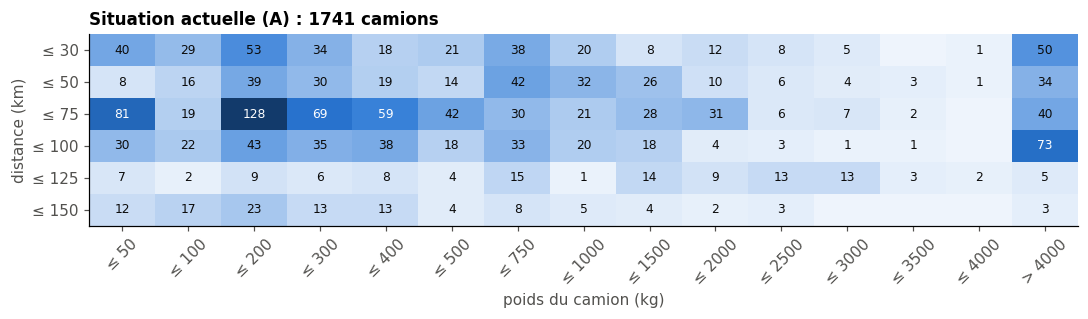

In [8]:
km_label = lambda k: f"≤ {k:g}"
kg_labels = [f"≤ {k:g}" if np.isfinite(k) else "> 4000" for k in tariff.kg]


def grid_counts(trucks: pd.DataFrame) -> pd.DataFrame:
    rows = tariff.km[np.searchsorted(tariff.km, trucks["distance"].to_numpy(float), side="left")]
    cols = np.searchsorted(tariff.kg, trucks["weight"].to_numpy(float), side="left")
    table = pd.crosstab(rows, cols).reindex(columns=range(len(tariff.kg)), fill_value=0)
    table.columns = kg_labels
    table.index = [km_label(k) for k in table.index]
    return table


def plot_grids(grids: dict[str, pd.DataFrame]):
    rows = sorted({r for g in grids.values() for r in g.index}, key=lambda s: float(s[2:]))
    grids = {name: g.reindex(index=rows, fill_value=0) for name, g in grids.items()}
    vmax = max(g.to_numpy().max() for g in grids.values())
    fig, axes = plt.subplots(len(grids), 1, figsize=(10, 3 * len(grids)), sharex=True, squeeze=False)
    for ax, (name, grid) in zip(axes[:, 0], grids.items()):
        ax.imshow(grid.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=vmax, aspect="auto")
        for r in range(grid.shape[0]):
            for c in range(grid.shape[1]):
                if v := grid.iat[r, c]:
                    ax.text(c, r, v, ha="center", va="center", fontsize=8, color="white" if v > vmax * 0.45 else "#0b0b0b")
        ax.set_yticks(range(len(rows)), rows); ax.set_ylabel("distance (km)"); ax.set_title(name); ax.grid(False)
    axes[-1, 0].set_xticks(range(len(kg_labels)), kg_labels, rotation=45); axes[-1, 0].set_xlabel("poids du camion (kg)")
    plt.tight_layout(); plt.show()


grid_A = grid_counts(trucks_A)  # trucks of the reference, loaded like the plan
plot_grids({f"Situation actuelle (A) : {len(trucks_A)} camions": grid_A})

### 4.3 Carte de chaleur : camions reçus par usine et par jour

Aujourd'hui, chaque besoin est livré le jour même : la charge des quais suit le planning, avec de fortes pointes certains jours.

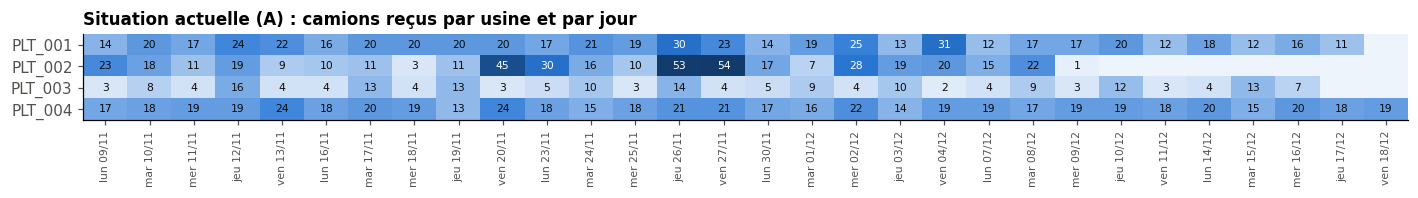

In [9]:
def plot_calendar(loads: dict[str, pd.DataFrame]):
    days = sorted({d for load in loads.values() for d in load.index})
    loads = {name: load.reindex(days, fill_value=0) for name, load in loads.items()}
    vmax = max(load.to_numpy().max() for load in loads.values())
    fig, axes = plt.subplots(len(loads), 1, figsize=(13, 1.9 * len(loads)), squeeze=False)
    for ax, (name, load) in zip(axes[:, 0], loads.items()):
        matrix = load.T.to_numpy()
        ax.imshow(matrix, cmap=SEQUENTIAL, vmin=0, vmax=vmax, aspect="auto")
        for r in range(matrix.shape[0]):
            for c in range(matrix.shape[1]):
                if matrix[r, c]:
                    ax.text(c, r, int(matrix[r, c]), ha="center", va="center", fontsize=7,
                            color="white" if matrix[r, c] > vmax * 0.45 else "#0b0b0b")
        ax.set_yticks(range(len(load.columns)), load.columns); ax.set_title(name); ax.grid(False)
        ax.set_xticks(range(len(days)), [f"{pl.DAY_NAMES[d.weekday()][:3]} {d:%d/%m}" for d in days], rotation=90, fontsize=7)
    plt.tight_layout(); plt.show()


load_A = pl.plant_day_load(baseline)
plot_calendar({"Situation actuelle (A) : camions reçus par usine et par jour": load_A})

## 5. Résultats

On calcule trois plans à partir des mêmes candidats :
- **B0 - sans lissage** : chaque couple prend son plan le moins cher, sans regarder les autres ;
- **B1 - lissage gratuit (plan retenu)** : budget 0, le lissage ne choisit qu'entre plans de même coût, sans augmenter le profil d'un couple ;
- **B2 - petit lissage** : budget de `SMALL_SMOOTHING_BUDGET` (0,5 %) du coût pour mieux répartir.

In [10]:
t0 = perf_counter()
plans = {
    "B0 - sans lissage": pl.choose_profiles(candidates, cfg),
    "B1 - lissage gratuit (retenu)": pl.smooth(candidates, cfg),
    "B2 - petit lissage": pl.smooth(candidates, replace(cfg, smoothing_budget=SMALL_SMOOTHING_BUDGET)),
}
configs = {"B0 - sans lissage": replace(cfg, smoothing=False), "B1 - lissage gratuit (retenu)": cfg,
           "B2 - petit lissage": replace(cfg, smoothing_budget=SMALL_SMOOTHING_BUDGET)}
exports = {name: pl.export(lines, p, "B", tariff, cfg) for name, p in plans.items()}
RETAINED = "B1 - lissage gratuit (retenu)"
plans_B, (trucks_B, alloc_B) = plans[RETAINED], exports[RETAINED]
logger.info("3 plans in %.1f s", perf_counter() - t0)

second_week = pd.Timestamp(lines["date"].min()) + pd.Timedelta(days=7)
def indicators(trucks, alloc, deliveries=None):
    load = pl.plant_day_load(trucks)
    n_trucks = int(trucks["trucks"].sum()) if "trucks" in trucks else len(trucks)
    return {
        "livraisons (couple × jour)": len(deliveries) if deliveries is not None else trucks.groupby(["supplier_id", "plant", "date"]).ngroups,
        "camions": n_trucks, "coût (EUR)": trucks["cost"].sum(),
        "saving vs A (EUR)": baseline["cost"].sum() - trucks["cost"].sum(),
        "saving vs A (%)": 100 * (1 - trucks["cost"].sum() / baseline["cost"].sum()),
        "coût par camion (EUR)": trucks["cost"].sum() / n_trucks,
        "poids moyen d'un camion (kg)": lines["weight"].sum() / n_trucks,
        "pic : camions / jour / usine": load.max().max(),
        "pic semaines 2 à 6": load.loc[second_week:].max().max(),
        "avance moyenne (jours)": 0.0 if alloc is None else alloc["advance_days"].mean(),
    }

comparison = pd.DataFrame({"A - actuel": indicators(baseline, None, baseline),
                           **{name: indicators(t, a) for name, (t, a) in exports.items()}})
comparison

15:19:09 INFO    3 plans in 248.0 s


,A - actuel,B0 - sans lissage,B1 - lissage gratuit (retenu),B2 - petit lissage
livraisons (couple × jour),1 665.00,645.00,642.00,651.00
camions,1 741.00,757.00,757.00,766.00
coût (EUR),176 724.61,110 457.86,110 457.86,110 992.20
saving vs A (EUR),0.00,66 266.75,66 266.75,65 732.41
saving vs A (%),0.00,37.50,37.50,37.19
coût par camion (EUR),101.51,145.92,145.92,144.90
poids moyen d'un camion (kg),2 798.08,6 435.22,6 435.22,6 359.61
pic : camions / jour / usine,54.00,40.00,37.00,14.00
pic semaines 2 à 6,54.00,40.00,37.00,14.00
avance moyenne (jours),0.00,2.95,3.08,3.08


In [11]:
saving = baseline["cost"].sum() - trucks_B["cost"].sum()
display(Markdown(
    f"**Plan retenu (B1) : {eur(trucks_B['cost'].sum())} EUR sur 6 semaines contre {eur(baseline['cost'].sum())} EUR aujourd'hui, "
    f"soit un saving de {eur(saving)} EUR (−{pct(100 * saving / baseline['cost'].sum())} %)**, avec {len(trucks_B)} camions au lieu de "
    f"{int(baseline['trucks'].sum())}."))

**Plan retenu (B1) : 110 458 EUR sur 6 semaines contre 176 725 EUR aujourd'hui, soit un saving de 66 267 EUR (−37,5 %)**, avec 757 camions au lieu de 1741.

### 5.1 Répartition des profils

Le profil d'un couple est le plus grand nombre de livraisons qu'il fait en une semaine. Le graphique compare la situation actuelle (profil mesuré au Milestone 2) et les trois plans.

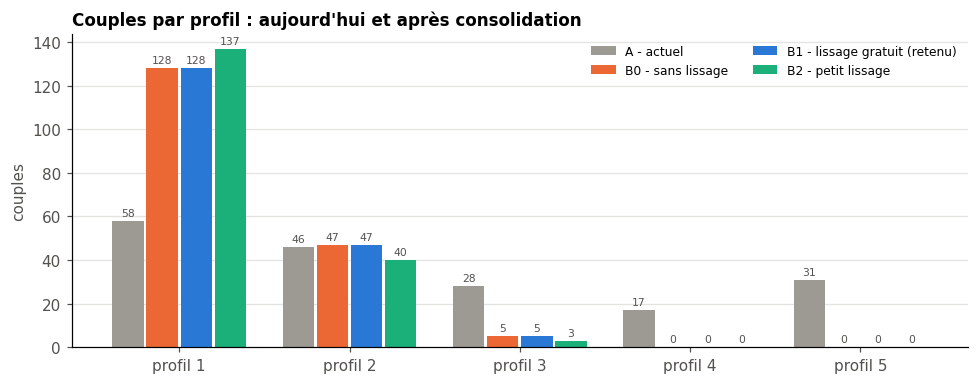

In [12]:
current_profile = baseline.assign(week=lambda d: d["date"] - pd.to_timedelta(d["date"].dt.day_of_week, unit="D")) \
    .groupby([*pl.COUPLE, "week"]).size().groupby(level=[0, 1]).max()
profile_counts = pd.DataFrame({"A - actuel": current_profile.value_counts(),
                               **{name: pd.Series([p.frequency for p in pp.values()]).value_counts() for name, pp in plans.items()}}
                              ).reindex(range(1, 6), fill_value=0).fillna(0).astype(int)
profile_counts.index.name = "profil (livraisons max / semaine)"

fig, ax = plt.subplots(figsize=(9, 3.6))
x, width = np.arange(len(profile_counts)), 0.2
for k, name in enumerate(profile_counts.columns):
    bars = ax.bar(x + (k - 1.5) * width, profile_counts[name], width=width * 0.92, color=SCENARIO_COLORS[name], label=name)
    ax.bar_label(bars, padding=2, fontsize=7, color=MUTED)
ax.set_xticks(x, [f"profil {p}" for p in profile_counts.index]); ax.set_ylabel("couples")
ax.set_title("Couples par profil : aujourd'hui et après consolidation"); ax.legend(fontsize=8, ncols=2)
plt.tight_layout(); plt.show()

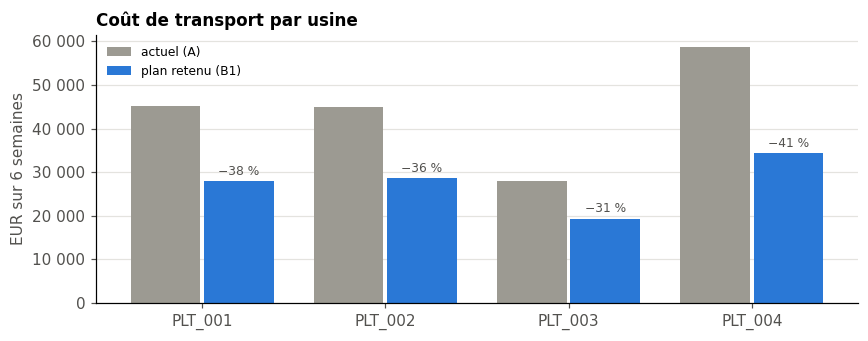

In [13]:
by_plant = pd.DataFrame({
    "coût actuel (EUR)": baseline.groupby("plant")["cost"].sum(),
    "coût plan retenu (EUR)": trucks_B.groupby("plant")["cost"].sum(),
    "camions actuels": baseline.groupby("plant")["trucks"].sum(),
    "camions plan retenu": trucks_B.groupby("plant").size(),
})
by_plant["saving (EUR)"] = by_plant["coût actuel (EUR)"] - by_plant["coût plan retenu (EUR)"]
by_plant["saving (%)"] = 100 * by_plant["saving (EUR)"] / by_plant["coût actuel (EUR)"]

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(by_plant))
ax.bar(x - 0.2, by_plant["coût actuel (EUR)"], width=0.38, color=SCENARIO_COLORS["A - actuel"], label="actuel (A)")
bars = ax.bar(x + 0.2, by_plant["coût plan retenu (EUR)"], width=0.38, color=SCENARIO_COLORS[RETAINED], label="plan retenu (B1)")
ax.bar_label(bars, labels=[f"−{s:.0f} %" for s in by_plant["saving (%)"]], padding=2, fontsize=8, color=MUTED)
ax.set_xticks(x, by_plant.index); ax.set_ylabel("EUR sur 6 semaines"); ax.set_title("Coût de transport par usine"); ax.legend(fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: eur(v))
plt.tight_layout(); plt.show()

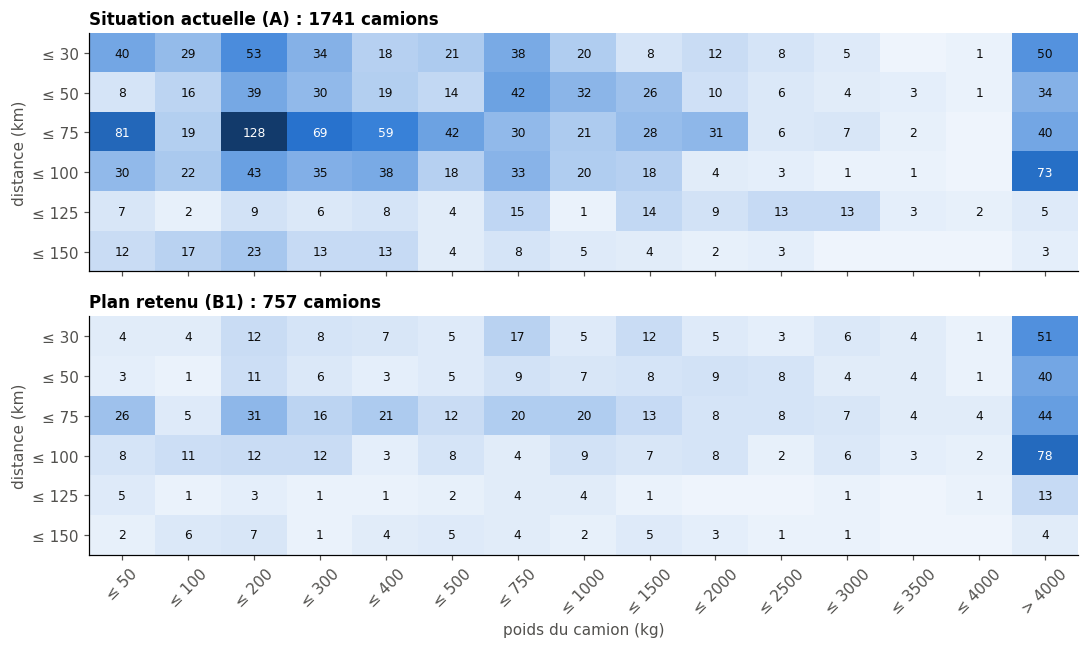

In [14]:
grid_B = grid_counts(trucks_B)
plot_grids({f"Situation actuelle (A) : {len(trucks_A)} camions": grid_A,
            f"Plan retenu (B1) : {len(trucks_B)} camions": grid_B})

## 6. Lissage : sans lissage, lissage gratuit, petit lissage

Le lissage (RG09) répartit les jours de livraison entre les couples d'une même usine. On compare les camions reçus **par jour de la semaine** et **par jour du calendrier**, usine par usine, pour la situation actuelle et les trois plans.

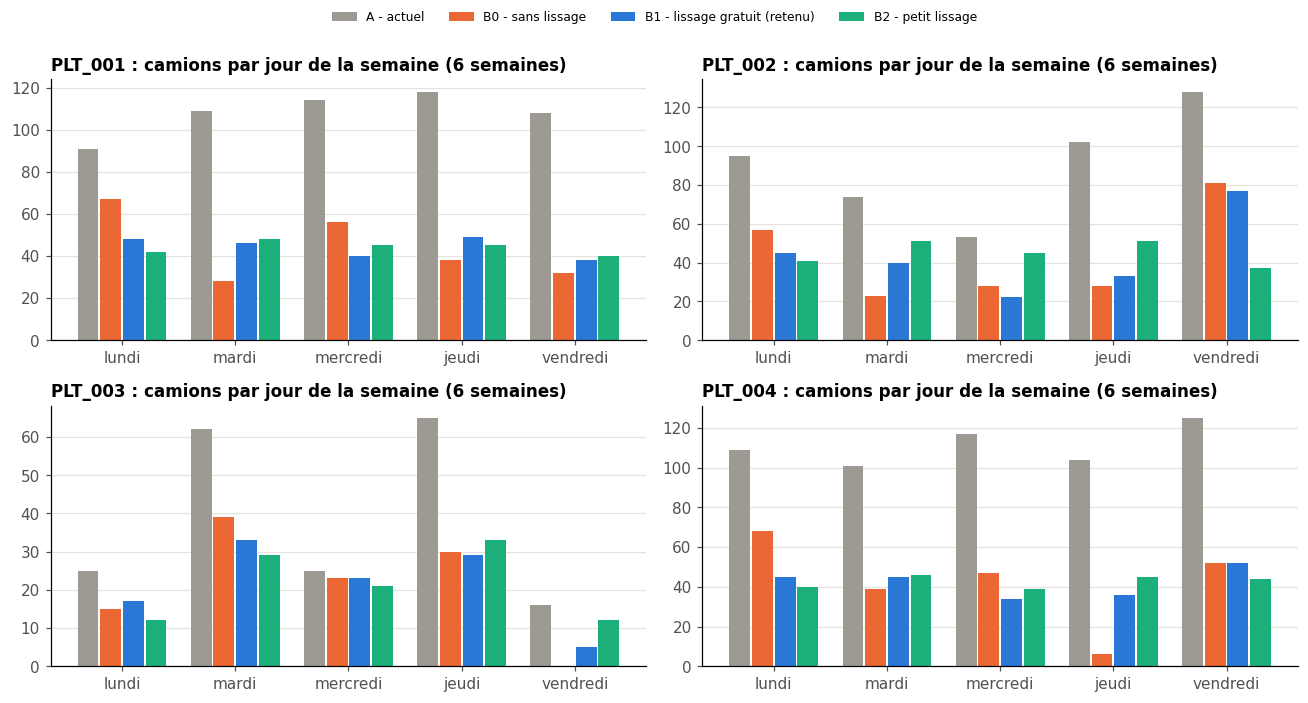

In [15]:
scenario_trucks = {"A - actuel": baseline.rename(columns={"trucks": "n"}).assign(weekday=lambda d: d["weekday"]),
                   **{name: t.assign(n=1) for name, (t, _) in exports.items()}}
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharey=False)
x, width = np.arange(5), 0.2
for ax, plant in zip(axes.flat, sorted(PLANT_COLORS)):
    for k, (name, t) in enumerate(scenario_trucks.items()):
        per_day = t[t["plant"] == plant].groupby("weekday")["n"].sum().reindex(pl.DAY_NAMES, fill_value=0)
        ax.bar(x + (k - 1.5) * width, per_day, width=width * 0.92, color=SCENARIO_COLORS[name], label=name)
    ax.set_xticks(x, pl.DAY_NAMES); ax.set_title(f"{plant} : camions par jour de la semaine (6 semaines)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), ncols=4, loc="upper center", fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

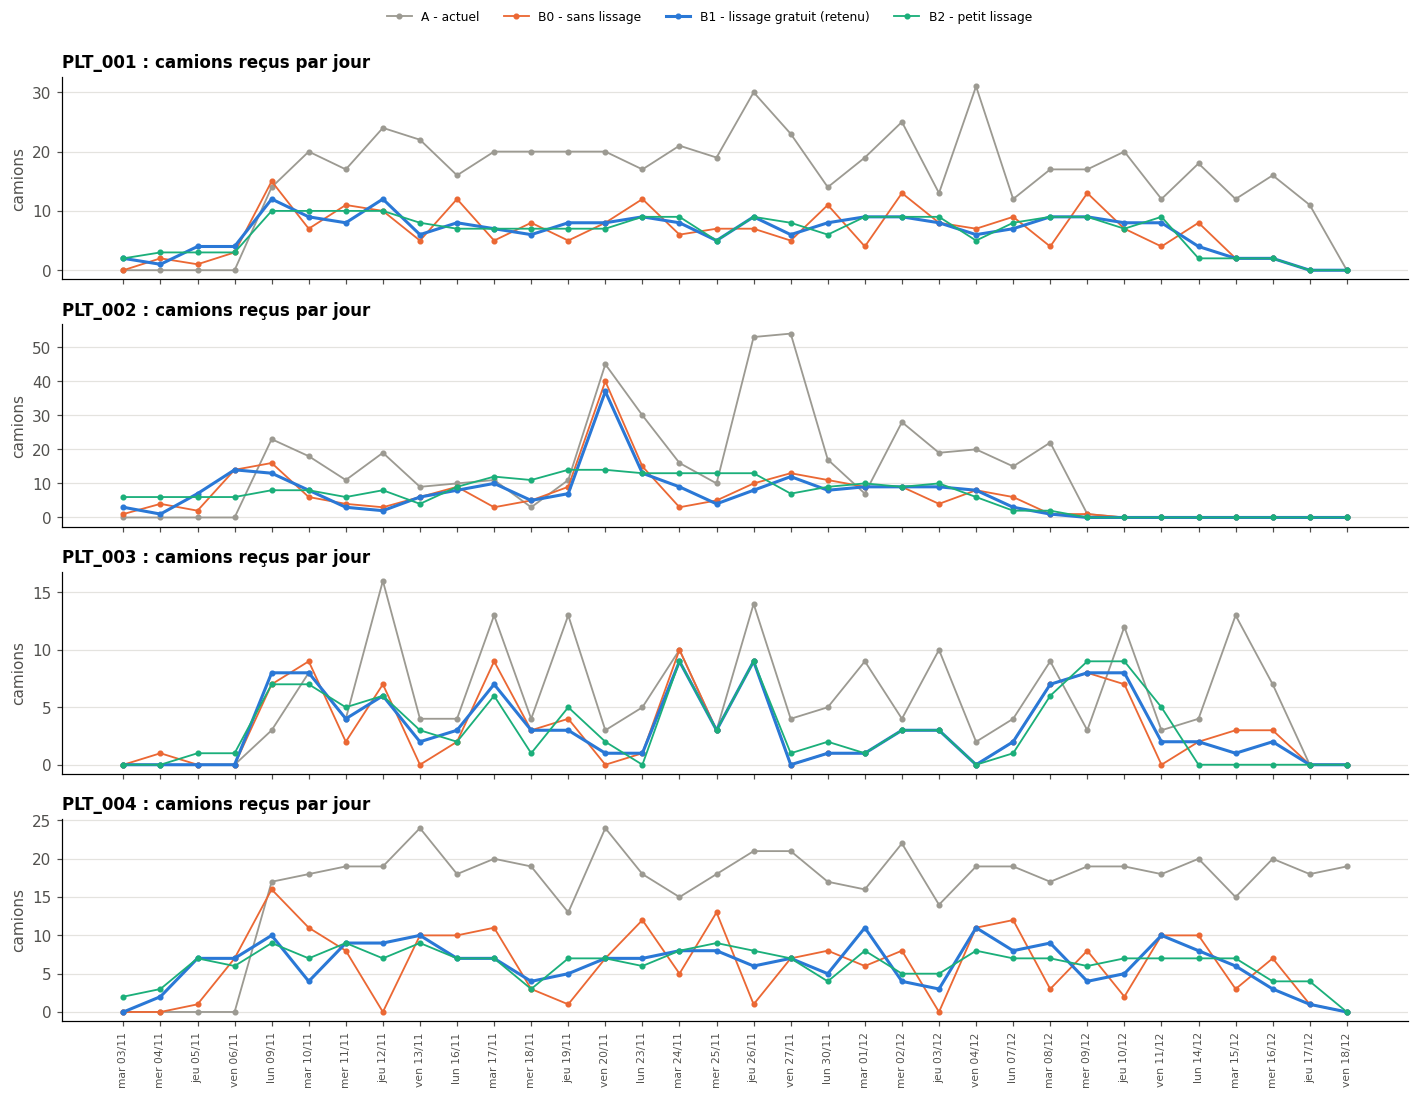

In [16]:
loads = {name: pl.plant_day_load(baseline if name == "A - actuel" else exports[name][0]) for name in SCENARIO_COLORS}
days = sorted({d for load in loads.values() for d in load.index})
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, plant in zip(axes, sorted(PLANT_COLORS)):
    for name, load in loads.items():
        series = load.reindex(days, fill_value=0)[plant]
        ax.plot(range(len(days)), series, marker="o", markersize=3, lw=2 if name == RETAINED else 1.2,
                color=SCENARIO_COLORS[name], label=name)
    ax.set_title(f"{plant} : camions reçus par jour"); ax.set_ylabel("camions")
fig.legend(*axes[0].get_legend_handles_labels(), ncols=4, loc="upper center", fontsize=8)
axes[-1].set_xticks(range(len(days)), [f"{pl.DAY_NAMES[d.weekday()][:3]} {d:%d/%m}" for d in days], rotation=90, fontsize=7)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

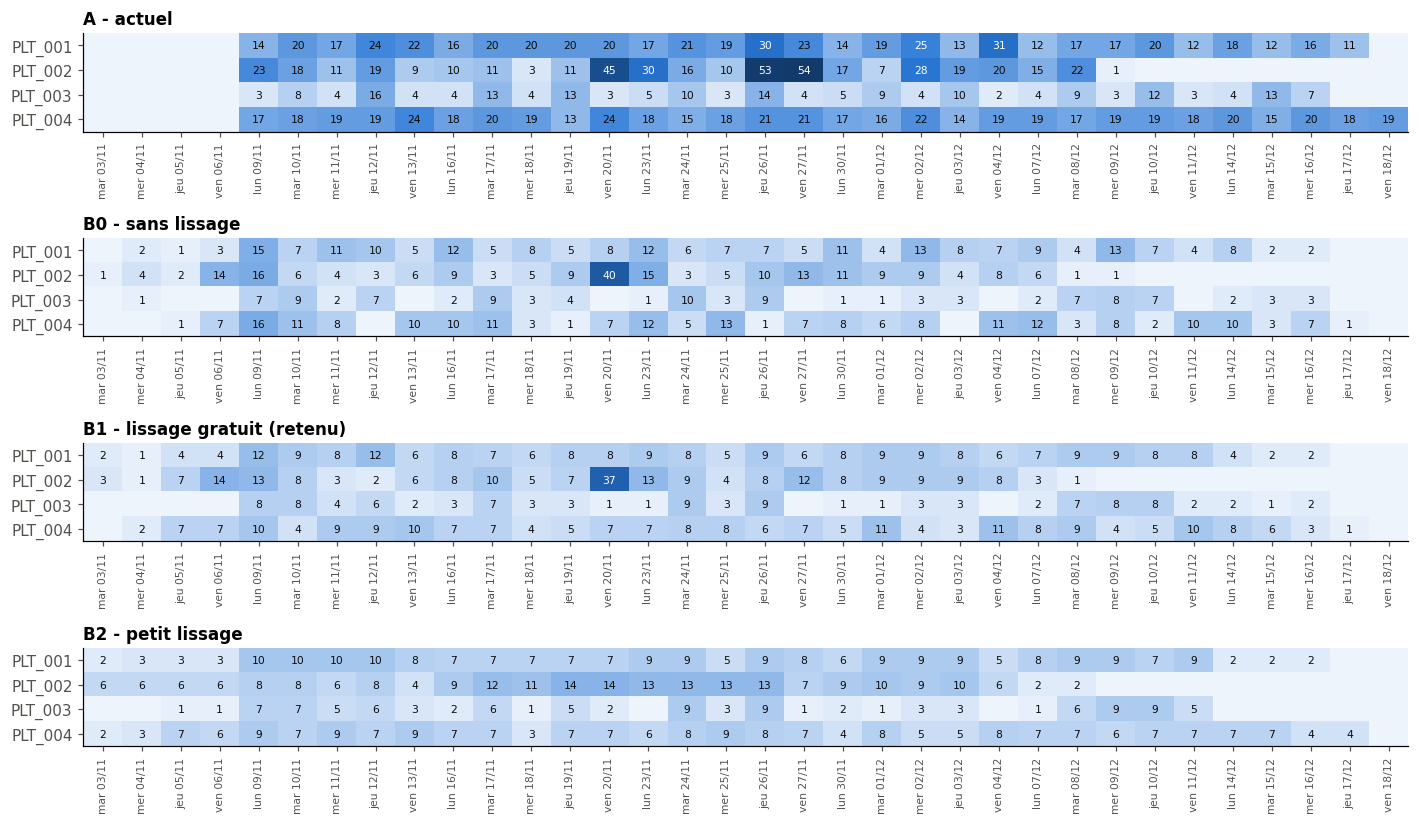

In [17]:
plot_calendar({name: loads[name] for name in ["A - actuel", "B0 - sans lissage", RETAINED, "B2 - petit lissage"]})

In [18]:
b0, b1, b2 = (comparison[name] for name in plans)
moved = sum(plans[RETAINED][k].profile != plans["B0 - sans lissage"][k].profile for k in plans_B)
display(Markdown(
    f"**Lecture :** sans lissage, le jour le plus chargé reçoit {b0['pic : camions / jour / usine']:.0f} camions dans une usine. "
    f"Le lissage gratuit déplace les jours de {moved} couples **sans changer le coût** ({eur(b1['coût (EUR)'])} EUR) et ramène ce pic à "
    f"{b1['pic : camions / jour / usine']:.0f}. Le petit lissage ({pct(100 * SMALL_SMOOTHING_BUDGET)} % de budget) coûte "
    f"{eur(b2['coût (EUR)'] - b1['coût (EUR)'])} EUR de plus et descend le pic à {b2['pic : camions / jour / usine']:.0f} "
    f"({b2['pic semaines 2 à 6']:.0f} sur les semaines 2 à 6, contre {comparison.loc['pic semaines 2 à 6', 'A - actuel']:.0f} aujourd'hui). "
    f"Les livraisons pouvant commencer le 02/11 (H11), les besoins du lundi 09/11 peuvent partir la semaine précédente : la 1re semaine n'impose plus de pic."))

**Lecture :** sans lissage, le jour le plus chargé reçoit 40 camions dans une usine. Le lissage gratuit déplace les jours de 55 couples **sans changer le coût** (110 458 EUR) et ramène ce pic à 37. Le petit lissage (0,5 % de budget) coûte 534 EUR de plus et descend le pic à 14 (14 sur les semaines 2 à 6, contre 54 aujourd'hui). Les livraisons pouvant commencer le 02/11 (H11), les besoins du lundi 09/11 peuvent partir la semaine précédente : la 1re semaine n'impose plus de pic.

## 7. Indicateurs complémentaires

Des indicateurs qui aident à juger la qualité du plan retenu (B1), au-delà du coût.

In [19]:
imputed_only = trucks_B[trucks_B["imputed_full_truck"] & (trucks_B["lines"] == 1)]
weight_A = trucks_A["weight"]
fluid_gap = 0
for (s, p, d), g in alloc_B.groupby(["supplier_id", "plant", "delivery_date"]):
    fluid_gap += g["truck_id"].nunique() - int(np.ceil(max(g["weight"].sum() / cfg.truck_kg, g["volume"].sum() / cfg.truck_m3) - 1e-9))
extra = pd.DataFrame({"valeur": {
    "camions portant une seule ligne complétée par un camion plein (H05)": len(imputed_only),
    "part du coût du plan due à ces camions (%)": 100 * imputed_only["cost"].sum() / trucks_B["cost"].sum(),
    "camions au-dessus du minimum théorique, départ par départ (chargement)": fluid_gap,
    "camions de plus de 4 000 kg, tarif forfaitaire - actuel (%)": 100 * (weight_A > 4000).mean(),
    "camions de plus de 4 000 kg, tarif forfaitaire - plan (%)": 100 * (trucks_B["weight"] > 4000).mean(),
    "coût par tonne livrée - actuel (EUR/t)": baseline["cost"].sum() / (lines["weight"].sum() / 1000),
    "coût par tonne livrée - plan (EUR/t)": trucks_B["cost"].sum() / (lines["weight"].sum() / 1000),
    "départs à plusieurs camions": int((trucks_B.groupby(["supplier_id", "plant", "date"]).size() > 1).sum()),
    "camions livrés avant le premier besoin (H11)": int((trucks_B["date"] < lines["date"].min()).sum()),
    "besoins livrés avec 5 jours d'avance ou plus (%)": 100 * (alloc_B["advance_days"] >= 5).mean(),
}})
extra

,valeur
camions portant une seule ligne complétée par un camion plein (H05),134.00
part du coût du plan due à ces camions (%),30.33
"camions au-dessus du minimum théorique, départ par départ (chargement)",0.00
"camions de plus de 4 000 kg, tarif forfaitaire - actuel (%)",11.77
"camions de plus de 4 000 kg, tarif forfaitaire - plan (%)",30.38
coût par tonne livrée - actuel (EUR/t),36.28
coût par tonne livrée - plan (EUR/t),22.67
départs à plusieurs camions,56.00
camions livrés avant le premier besoin (H11),52.00
besoins livrés avec 5 jours d'avance ou plus (%),32.49


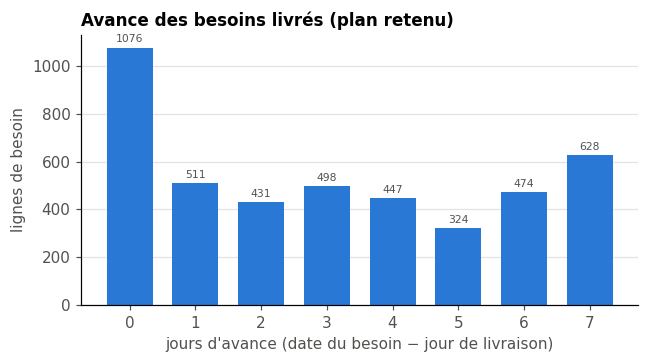

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.4))
advance = alloc_B["advance_days"].value_counts().reindex(range(cfg.max_advance_days + 1), fill_value=0)
bars = ax.bar(advance.index, advance, color=SCENARIO_COLORS[RETAINED], width=0.7)
ax.bar_label(bars, padding=2, fontsize=7, color=MUTED)
ax.set_xlabel("jours d'avance (date du besoin − jour de livraison)"); ax.set_ylabel("lignes de besoin")
ax.set_title("Avance des besoins livrés (plan retenu)")
plt.tight_layout(); plt.show()

## 8. Les trois sorties

### Sortie 1 : le profil à appliquer à chaque couple

`profile` = plus grand nombre de livraisons en une semaine ; `profile_days` = l'ensemble fixe de jours ; `weekly_pattern` = livraisons de chaque semaine du plan, à partir de la semaine du 02/11 (H11) ; `current_weekly_pattern` commence donc par un 0 ; `current_weekly_pattern` = livraisons de chaque semaine aujourd'hui ; `reason` = justification (EF10).

In [21]:
summary_B = pl.couple_summary(lines, baseline, plans_B, candidates, plans["B0 - sans lissage"], cfg)
TOP = summary_B.head(5)  # the 5 couples with the largest saving, shown in the three outputs

output_1 = summary_B[["supplier_id", "plant", "distance", "current_profile", "current_weekly_pattern", "profile", "profile_days",
                      "weekly_pattern", "trucks_per_active_week", "mean_fill_weight_pct",
                      "mean_advance_days", "reason"]].sort_values(["plant", "supplier_id"]).reset_index(drop=True)
print("Profils (livraisons max / semaine -> couples) :", output_1["profile"].value_counts().sort_index().to_dict())

day_names = lambda days: " + ".join(d.capitalize() for d in days.split(" + ")) if isinstance(days, str) else days
pd.DataFrame({
    "Fournisseur": TOP["supplier_id"],
    "Usine": TOP["plant"],
    "Distance (km)": TOP["distance"],
    "Livraisons / sem. actuelles": TOP["current_profile"],
    "Fréquence cible (livraisons / sem.)": TOP["profile"],
    "Jour": TOP["profile_days"].map(day_names),
    "Camions / sem.": TOP["trucks_per_active_week"],
    "Remplissage poids (%)": TOP["mean_fill_weight_pct"].round(1),
}).reset_index(drop=True)

Profils (livraisons max / semaine -> couples) : {1: 128, 2: 47, 3: 5}


,Fournisseur,Usine,Distance (km),Livraisons / sem. actuelles,Fréquence cible (livraisons / sem.),Jour,Camions / sem.,Remplissage poids (%)
0,SUP_00085,PLT_004,121.00,5,1,Lundi,1.00,48.20
1,SUP_00146,PLT_002,122.00,5,2,Lundi + Mardi,1.25,42.70
2,SUP_00059,PLT_003,122.00,5,1,Mercredi,1.00,19.00
3,SUP_00144,PLT_001,38.00,5,2,Lundi + Mercredi,1.40,54.80
4,SUP_00080,PLT_004,40.00,5,1,Vendredi,1.00,18.80


### Sortie 2 : les materials regroupés dans chaque camion

Au format du sujet : pour chaque camion, chaque material et chaque quai, les jours de besoin regroupés, la quantité et le poids. Exemple : le premier camion de SUP_00085 → PLT_004 (les 10 materials les plus lourds, puis le reste regroupé) ; le détail ligne par ligne (date de besoin, avance, règle de livraison) est dans `allocations`.

In [22]:
output_2 = pl.truck_contents(alloc_B)
truck = trucks_B.loc[trucks_B["supplier_id"].eq("SUP_00085") & trucks_B["plant"].eq("PLT_004")].iloc[0]
content = output_2[output_2["truck_id"].eq(truck["truck_id"])].sort_values("weight", ascending=False)
months = {d.split("/")[1] for days in content["need_days"] for d in days.split(", ")}
month_names = {"11": "nov.", "12": "déc."}
same_month = len(months) == 1
need_days = content["need_days"].map(lambda days: ", ".join(str(int(d.split("/")[0])) for d in days.split(", ")) if same_month else days)
shown = pd.DataFrame({"material": content["material"], "Quai": content["unloading_point"], "Besoins": need_days,
                      "Quantité": content["quantity"], "Poids (kg)": content["weight"]})
TOP_MATERIALS = 10
rest = shown.iloc[TOP_MATERIALS:]
rows = [shown.head(TOP_MATERIALS)]
if len(rest):
    rows.append(pd.DataFrame([{"material": f"{len(rest)} autres materials", "Quai": "", "Besoins": "",
                               "Quantité": rest["Quantité"].sum(), "Poids (kg)": rest["Poids (kg)"].sum()}]))
rows.append(pd.DataFrame([{"material": f"Total camion du {truck['weekday']} {truck['date']:%d/%m}", "Quai": "",
                           "Besoins": f"{int(content['need_lines'].sum())} lignes de besoin",
                           "Quantité": content["quantity"].sum(), "Poids (kg)": content["weight"].sum()}]))
table = pd.concat(rows, ignore_index=True).rename(columns={
    "Besoins": f"Besoins regroupés (jours de {month_names.get(months.pop(), '')})" if same_month else "Besoins regroupés"})
table["Poids (kg)"] = table["Poids (kg)"].round(0)
table

,material,Quai,Besoins regroupés (jours de nov.),Quantité,Poids (kg)
0,MAT_000298,ULP_0010,"9, 10, 11, 12, 13",1 374.00,4 701.00
1,MAT_000131,ULP_0010,"9, 11, 13",360.00,1 046.00
2,MAT_000455,ULP_0050,"10, 12, 13",1 350.00,977.00
3,MAT_000074,ULP_0050,"10, 12, 13",900.00,825.00
4,MAT_000066,ULP_0035,12,1 200.00,731.00
5,MAT_000808,ULP_0050,"10, 13",2 000.00,663.00
6,MAT_000798,ULP_0050,"9, 13",480.00,597.00
7,MAT_000966,ULP_0050,"9, 11",1 200.00,527.00
8,MAT_000223,ULP_0035,9,900.00,439.00
9,MAT_000621,ULP_0050,10,450.00,385.00


### Sortie 3 : le saving potentiel par couple

Les 5 couples qui rapportent le plus : coût de transport sur les 6 semaines, aujourd'hui et après consolidation.

Saving total : 66 267 EUR | couples sans saving : 39 | couples plus chers qu'aujourd'hui : 0


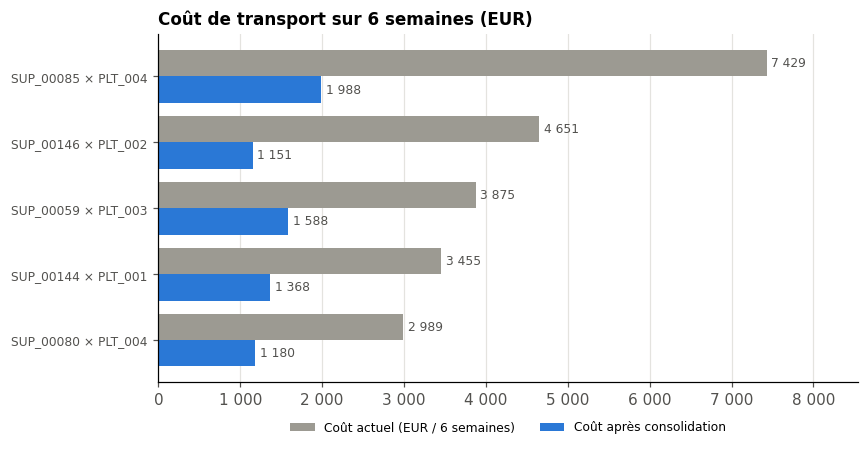

In [23]:
output_3 = summary_B[["supplier_id", "plant", "distance", "deliveries_before", "deliveries_after", "trucks_before", "trucks_after",
                      "imputed_full_truck_lines", "cost_before", "cost_after", "saving", "saving_pct"]]
assert np.isclose(output_3["saving"].sum(), baseline["cost"].sum() - trucks_B["cost"].sum())
print(f"Saving total : {eur(output_3['saving'].sum())} EUR | couples sans saving : {(output_3['saving'] <= 0.01).sum()} "
      f"| couples plus chers qu'aujourd'hui : {(output_3['saving'] < -0.01).sum()}")

labels = (TOP["supplier_id"] + " × " + TOP["plant"]).tolist()[::-1]
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4.2))
for offset, column, color, label in [(0.2, "cost_before", SCENARIO_COLORS["A - actuel"], "Coût actuel (EUR / 6 semaines)"),
                                     (-0.2, "cost_after", SCENARIO_COLORS[RETAINED], "Coût après consolidation")]:
    values = TOP[column].to_numpy()[::-1]
    bars = ax.barh(y + offset, values, height=0.4, color=color, label=label)
    ax.bar_label(bars, labels=[eur(v) for v in values], padding=3, fontsize=8, color=MUTED)
ax.set_yticks(y, labels, fontsize=8); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: eur(v)); ax.set_xlim(0, TOP["cost_before"].max() * 1.15)
ax.set_title("Coût de transport sur 6 semaines (EUR)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=2, frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [24]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
files = {
    "sortie1_profils.csv": output_1,
    "sortie2_contenu_camions.csv": output_2,
    "sortie2_camions.csv": trucks_B,
    "sortie2_affectations.csv": alloc_B,
    "sortie3_saving.csv": output_3,
}
for name, frame in files.items():
    frame.to_csv(OUTPUT_DIR / name, index=False, date_format="%Y-%m-%d")
logger.info("Files written to %s", OUTPUT_DIR.as_posix())
pd.DataFrame({"lignes": {name: len(frame) for name, frame in files.items()}})

15:19:13 INFO    Files written to ../data


,lignes
sortie1_profils.csv,180
sortie2_contenu_camions.csv,2966
sortie2_camions.csv,757
sortie2_affectations.csv,4389
sortie3_saving.csv,180


## 9. Synthèse et limites

In [25]:
r = comparison[RETAINED]
display(Markdown(f'''
- **Plan retenu :** {eur(r["coût (EUR)"])} EUR sur 6 semaines au lieu de {eur(baseline["cost"].sum())} EUR, soit **{eur(r["saving vs A (EUR)"])} EUR de saving (−{pct(r["saving vs A (%)"])} %)**, avec {int(r["camions"])} camions au lieu de {int(baseline["trucks"].sum())} et {int(r["livraisons (couple × jour)"])} livraisons au lieu de {len(baseline)}.
- **Optimisation :** jours de départ par programmation dynamique exacte, affectation des besoins améliorée par recherche locale (RG06 assouplie), lissage résolu par programme linéaire en nombres entiers (optimum prouvé sauf avertissement dans le journal).
- **Profils :** {", ".join(f"{n} couples en profil {p}" for p, n in output_1["profile"].value_counts().sort_index().items())}.
- **Lissage :** gratuit dans le plan retenu (pic {r["pic : camions / jour / usine"]:.0f} camions / jour / usine) ; avec {pct(100 * SMALL_SMOOTHING_BUDGET)} % de budget, pic {comparison.loc["pic : camions / jour / usine", "B2 - petit lissage"]:.0f} pour {eur(comparison.loc["coût (EUR)", "B2 - petit lissage"] - r["coût (EUR)"])} EUR de plus.
'''))


- **Plan retenu :** 110 458 EUR sur 6 semaines au lieu de 176 725 EUR, soit **66 267 EUR de saving (−37,5 %)**, avec 757 camions au lieu de 1741 et 642 livraisons au lieu de 1665.
- **Optimisation :** jours de départ par programmation dynamique exacte, affectation des besoins améliorée par recherche locale (RG06 assouplie), lissage résolu par programme linéaire en nombres entiers (optimum prouvé sauf avertissement dans le journal).
- **Profils :** 128 couples en profil 1, 47 couples en profil 2, 5 couples en profil 3.
- **Lissage :** gratuit dans le plan retenu (pic 37 camions / jour / usine) ; avec 0,5 % de budget, pic 14 pour 534 EUR de plus.


**Limites :**
- **Imputation (H05, H06) :** chaque ligne au poids inconnu occupe un camion entier, au plan comme à la référence (coût surestimé des deux côtés). Le vrai saving dépend des vrais poids de ces lignes, tant qu'ils ne sont pas connus.
- **Tarif forfaitaire au-delà de 4 000 kg (H18) :** à confirmer avec le transporteur ; il rend très rentable le regroupement des petites livraisons.
- **Anticipation en jours calendaires (H12) :** si le client confirmait 7 jours **ouvrés**, le moteur pourrait regrouper davantage (`max_advance_days`).
- **Stock et capacité de réception (H13) :** non limités ; l'avance moyenne et le pic par jour sont mesurés, pas contraints.
- **Préférence du client « des jours plutôt que des camions » :** non imposée par défaut (objectif coût) ; activable avec `overflow_first=True`.